# Toll Plaza Queue Simulation: How Many Booths at Peak Time?

A discrete-event simulation of an expressway toll plaza modelled as an M/M/c queue. Cars arrive at random, each open booth serves one car at a time for a random duration, and the program measures how long cars wait. The simulator is verified against the exact Erlang C formula, then used to find the smallest number of open booths that keeps the **average waiting time under 2 minutes** at peak time. Three extensions follow: time-varying (rush-hour) arrivals generated by thinning, a log-log error-scaling check, and a sensitivity analysis of the arrival and service rates.

**Headline result.** With the example peak demand of 6 cars/min and a service rate of 2.5 cars/min per booth, one or two booths cannot cope (the queue grows without limit). Three booths give a mean wait of about 0.43 minutes (95% CI in section 5), so **at least 3 booths** must be open.

> The notebook runs top to bottom with *Runtime → Run all* in about a minute on a free Colab runtime.

In [1]:
# Setup: only numpy, scipy and matplotlib are needed (all preinstalled on Colab)
import heapq, math, os, time
from collections import deque

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad

SEED = 42                         # master seed: every result below is reproducible
T_START = time.time()

# Figures are saved next to the notebook's repository (../figures) when it exists
FIG_DIR = "../figures" if os.path.isdir("../figures") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| seed", SEED)

numpy 2.5.3 | seed 42


## 1. Problem and question

An expressway toll plaza has several booths. At peak time cars arrive faster than at any other time, and if too few booths are open a long queue builds up and drivers lose time. Opening a booth costs staff, so the operator wants the **smallest number of open booths** that still keeps queues short.

**Question:** *How many toll booths must be open at peak time to keep the average waiting time under two minutes?*

Everything below serves this one question.

## 2. Model, assumptions and equations

**Assumptions**

1. **Poisson arrivals.** Cars arrive independently at a constant average rate $\lambda$ (peak-time value). Gaps between cars are exponential. This is the standard model for independent drivers over a short, stable period.
2. **Exponential service.** Each car's service time at a booth is exponential with mean $1/\mu$, independent of everything else. This is a simplification: real payment times are less variable than exponential, so the model errs on the safe (longer-wait) side.
3. **$c$ identical booths** sharing **one first-come-first-served queue**. Cars do not switch lanes, balk or renege.
4. **Unlimited waiting space**, so no car is turned away.
5. **Waiting time** means time from arrival until service starts (queueing delay $W_q$), not including the service itself.

This is the **M/M/c queue**. With $c=1$ it is the M/M/1 queue.

**Parameters** (example peak-time values; they are set in one place and can be changed)

| Symbol | Meaning | Units | Value |
|---|---|---|---|
| $\lambda$ | arrival rate | cars/min | 6.0 |
| $\mu$ | service rate of ONE booth | cars/min | 2.5 |
| $c$ | open booths | — | 1 to 5 |

**Traffic intensity**

$$\rho = \frac{\lambda}{c\,\mu}$$

If $\rho \ge 1$ cars arrive at least as fast as the booths can serve them and the queue has no steady state. If $\rho<1$ it settles down.

**Exact theory (Erlang C).** With offered load $a=\lambda/\mu$, the probability that an arriving car has to wait and the mean queueing delay are

$$C(c,a)=\frac{\dfrac{a^{c}}{c!}\,\dfrac{1}{1-\rho}}{\displaystyle\sum_{k=0}^{c-1}\frac{a^{k}}{k!}+\frac{a^{c}}{c!}\,\frac{1}{1-\rho}},\qquad W_q=\frac{C(c,a)}{c\mu-\lambda}\quad(\rho<1).$$

For $c=1$ this reduces to the M/M/1 result $W_q=\dfrac{\rho}{\mu-\lambda}$, which is used as an independent check.

**Random variate generation (inverse transform).** If $U\sim U(0,1)$ then

$$X=-\frac{\ln(1-U)}{\text{rate}}$$

is exponential with the given rate. This is used for every interarrival gap and every service time.

**Simulation method.** Discrete-event simulation with next-event time advance: the clock jumps from one event (a car arrives, a car finishes service) to the next using a future-event list, instead of ticking every second.

**Monte Carlo and confidence intervals.** One run is affected by randomness, so each scenario is simulated in $R$ independent replications with different seeds. The reported value is the mean of the replication means with a 95% $t$-based confidence interval.

**Concepts used:** discrete-event simulation (next-event time advance), random variate generation (inverse transform), Monte Carlo replications with confidence intervals, verification against analytic queueing results.

## 3. Implementation

Settings used throughout. Each replication simulates 40,000 cars; the first 5,000 are discarded as **warm-up** (the system starts empty, which biases early waits downwards).

In [2]:
LAMBDA, MU = 6.0, 2.5      # peak-time arrival rate and per-booth service rate (cars/min)
TARGET = 2.0               # waiting-time target (minutes)
N_CUST, WARMUP = 40_000, 5_000
R = 30                     # independent replications per scenario
TOL = 0.05                 # verification tolerance: 5% relative error

In [3]:
def expo(rng, rate, size):
    """Inverse-transform exponential variates: X = -ln(1-U)/rate."""
    return -np.log1p(-rng.random(size)) / rate      # log1p(-u) = ln(1-u), safe at u=0

DEPARTURE, ARRIVAL = 0, 1    # event types (departures first if two events tie)

def simulate_events(arrival_times, service_times, c):
    """Next-event M/M/c simulation. Returns the queueing delay of every car.

    Future-event list = a heap holding the NEXT arrival and one departure per busy booth.
    """
    n = len(arrival_times)
    waits = np.empty(n)
    fel = [(arrival_times[0], ARRIVAL, 0)]
    queue, busy = deque(), 0
    push, pop = heapq.heappush, heapq.heappop
    while fel:
        t, kind, i = pop(fel)                       # clock jumps to the next event
        if kind == ARRIVAL:
            if i + 1 < n:                           # schedule the next arrival
                push(fel, (arrival_times[i + 1], ARRIVAL, i + 1))
            if busy < c:                            # a booth is free: no wait
                busy += 1
                waits[i] = 0.0
                push(fel, (t + service_times[i], DEPARTURE, i))
            else:                                   # all booths busy: join the queue
                queue.append(i)
        else:                                       # a car finishes service
            if queue:                               # next car in line starts now
                j = queue.popleft()
                waits[j] = t - arrival_times[j]
                push(fel, (t + service_times[j], DEPARTURE, j))
            else:
                busy -= 1
    return waits

def simulate_fast(arrival_times, service_times, c):
    """Independent second implementation (earliest-free-booth recursion), used for
    cross-checking and for the long runs of the extensions."""
    free = [0.0] * c
    waits = np.empty(len(arrival_times))
    for i in range(len(arrival_times)):
        f = heapq.heappop(free)
        start = arrival_times[i] if arrival_times[i] > f else f
        waits[i] = start - arrival_times[i]
        heapq.heappush(free, start + service_times[i])
    return waits

def erlang_c(c, lam, mu):
    """Probability that an arriving car must wait (Erlang C)."""
    a, rho = lam / mu, lam / (c * mu)
    if rho >= 1:
        return 1.0
    top = a**c / math.factorial(c) / (1 - rho)
    return top / (sum(a**k / math.factorial(k) for k in range(c)) + top)

def wq_theory(c, lam, mu):
    """Exact mean queueing delay of an M/M/c queue (infinite if rho >= 1)."""
    return math.inf if lam >= c * mu else erlang_c(c, lam, mu) / (c * mu - lam)

def replicate(c, lam, mu, n=N_CUST, warmup=WARMUP, reps=R, seed=SEED, sim=simulate_events):
    """Run independent replications; return the mean wait of each (after warm-up)."""
    means = []
    for child in np.random.SeedSequence(seed).spawn(reps):   # independent streams
        rng = np.random.default_rng(child)
        arrivals = np.cumsum(expo(rng, lam, n))              # gaps -> arrival clock times
        services = expo(rng, mu, n)
        means.append(sim(arrivals, services, c)[warmup:].mean())
    return np.array(means)

def mean_ci(x, level=0.95):
    """Mean and half-width of the t-based confidence interval."""
    h = stats.t.ppf(0.5 + level / 2, len(x) - 1) * x.std(ddof=1) / math.sqrt(len(x))
    return x.mean(), h

## 4. Verification

The simulator must reproduce exact queueing theory before any of its answers can be trusted. Four independent checks follow.

**Check 1: M/M/1 against its closed form** $W_q=\rho/(\mu-\lambda)$.
**Check 2: M/M/c against Erlang C** for several booth counts and loads (all stable, $\rho<1$).
**Check 3: two independently coded simulators** must give identical waits for identical random inputs.
**Check 4: honest confidence intervals.** A 95% interval should contain the exact value in roughly 95% of repeated experiments.

In [4]:
# Check 1: M/M/1, lambda=2, mu=2.5 (rho=0.8) vs the closed form rho/(mu-lambda)
lam1, mu1 = 2.0, 2.5
exact_mm1 = (lam1 / mu1) / (mu1 - lam1)              # independent closed form = 1.6 min
sim1 = replicate(1, lam1, mu1, seed=SEED)
m1, h1 = mean_ci(sim1)
print(f"M/M/1  closed form = {exact_mm1:.4f} min | simulated = {m1:.4f} +/- {h1:.4f} (95% CI)")
assert abs(wq_theory(1, lam1, mu1) - exact_mm1) < 1e-12        # Erlang C reduces to M/M/1
assert abs(m1 - exact_mm1) / exact_mm1 < TOL, "M/M/1 simulation disagrees with theory"
print(f"PASS: relative error {abs(m1-exact_mm1)/exact_mm1:.2%} < {TOL:.0%}")

M/M/1  closed form = 1.6000 min | simulated = 1.5921 +/- 0.0280 (95% CI)
PASS: relative error 0.49% < 5%


In [5]:
# Check 2: M/M/c vs Erlang C for several configurations
cases = [(1, 2.0), (2, 4.0), (3, 6.0), (4, 8.0), (3, 4.5)]      # (c, lambda); mu = 2.5
rows = []
for k, (c, lam) in enumerate(cases):
    theory = wq_theory(c, lam, MU)
    m, h = mean_ci(replicate(c, lam, MU, seed=SEED + 100 + k))   # independent seed per case
    rel = abs(m - theory) / theory
    rows.append((c, lam, lam / (c * MU), theory, m, h, rel))
    assert rel < TOL, f"c={c}, lambda={lam}: simulation {m:.4f} vs Erlang C {theory:.4f}"

print(f"{'c':>2} {'lambda':>6} {'rho':>5} {'Erlang C':>9} {'simulated':>10} {'+/- 95%':>8} {'rel.err':>8}  in CI?")
for c, lam, rho, th, m, h, rel in rows:
    print(f"{c:>2} {lam:>6.1f} {rho:>5.2f} {th:>9.4f} {m:>10.4f} {h:>8.4f} {rel:>8.2%}  {abs(m-th) <= h}")
print(f"\nPASS: all {len(rows)} configurations within {TOL:.0%} of Erlang C")

 c lambda   rho  Erlang C  simulated  +/- 95%  rel.err  in CI?
 1    2.0  0.80    1.6000     1.5883   0.0317    0.73%  True
 2    4.0  0.80    0.7111     0.7042   0.0177    0.97%  True
 3    6.0  0.80    0.4315     0.4359   0.0140    1.03%  True
 4    8.0  0.80    0.2982     0.3008   0.0101    0.85%  True
 3    4.5  0.60    0.1182     0.1202   0.0025    1.63%  True

PASS: all 5 configurations within 5% of Erlang C


PASS: event-list simulator and earliest-free-booth recursion agree exactly for c = 1, 2, 3, 5


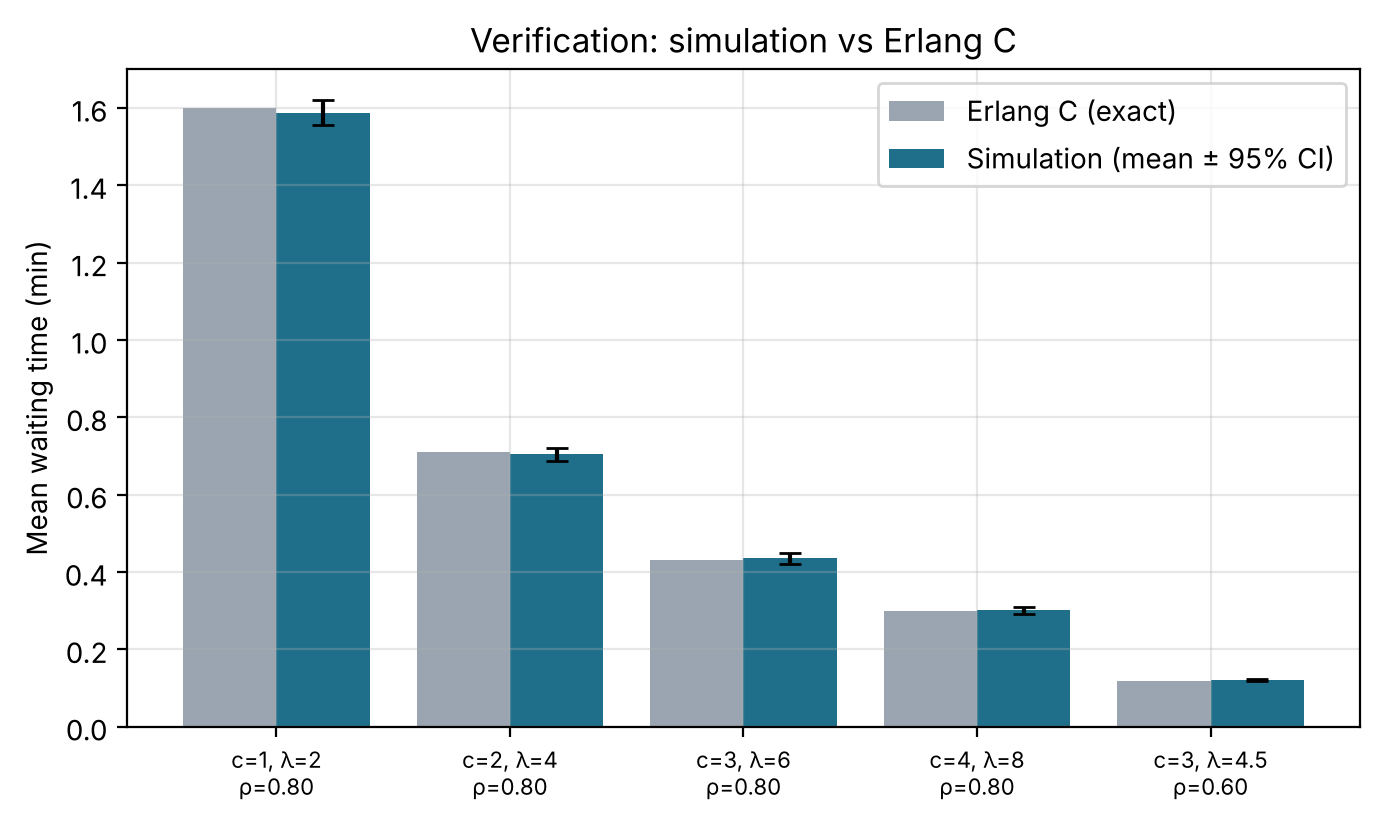

In [6]:
# Check 3: the two independently coded simulators give IDENTICAL waits for identical inputs
rng = np.random.default_rng(SEED)
arr = np.cumsum(expo(rng, LAMBDA, 20_000)); srv = expo(rng, MU, 20_000)
for c in (1, 2, 3, 5):
    assert np.array_equal(simulate_events(arr, srv, c), simulate_fast(arr, srv, c))
print("PASS: event-list simulator and earliest-free-booth recursion agree exactly for c = 1, 2, 3, 5")

# Verification figure
fig, ax = plt.subplots()
labels = [f"c={c}, λ={lam:g}\nρ={rho:.2f}" for c, lam, rho, *_ in rows]
x = np.arange(len(rows))
ax.bar(x - 0.2, [r[3] for r in rows], 0.4, label="Erlang C (exact)", color="#9aa5b1")
ax.bar(x + 0.2, [r[4] for r in rows], 0.4, yerr=[r[5] for r in rows], capsize=4,
       label="Simulation (mean ± 95% CI)", color="#1f6f8b")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Mean waiting time (min)"); ax.set_title("Verification: simulation vs Erlang C")
ax.legend(); plt.tight_layout(); savefig("verification.png"); plt.show()

In [7]:
# Check 4: does the "95%" interval really cover the exact value about 95% of the time?
# Repeat the whole three-booth experiment 100 times with fresh seeds and count the hits.
t0 = time.time()
theory3 = wq_theory(3, LAMBDA, MU)
TRIALS, hits, ests = 100, 0, []
for k in range(TRIALS):
    m, h = mean_ci(replicate(3, LAMBDA, MU, n=20_000, warmup=2_000, reps=20,
                             seed=10_000 + k, sim=simulate_fast))
    hits += abs(m - theory3) <= h
    ests.append(m)
print(f"exact {theory3:.4f} | mean of estimates {np.mean(ests):.4f} | CI coverage {hits}/{TRIALS} ({time.time() - t0:.0f} s)")
assert hits >= 85, "confidence intervals cover the exact value far less often than 95%"
print("PASS: coverage is close to the nominal 95% (consecutive cars are correlated, so a few points lower is expected)")

exact 0.4315 | mean of estimates 0.4303 | CI coverage 91/100 (18 s)
PASS: coverage is close to the nominal 95% (consecutive cars are correlated, so a few points lower is expected)


## 5. Experiment: waiting time against the number of booths

Fix the peak demand at $\lambda=6$ cars/min and $\mu=2.5$ cars/min per booth, and vary the number of open booths from 1 to 5. With $c=1$ or $2$, $\rho\ge1$, so no steady state exists: the mean wait of a *finite* run is only a snapshot of a queue that keeps growing (it would be larger in a longer run). For $c\ge3$, $\rho<1$ and the wait settles to a steady-state value that Erlang C predicts exactly.

In [8]:
results = {}
print(f"lambda = {LAMBDA}, mu = {MU}, target = {TARGET} min, {R} replications x {N_CUST:,} cars (first {WARMUP:,} discarded)\n")
print(f"{'c':>2} {'rho':>6} {'simulated mean wait':>22} {'Erlang C':>10}  verdict")
for c in range(1, 6):
    rho = LAMBDA / (c * MU)
    m, h = mean_ci(replicate(c, LAMBDA, MU))
    th = wq_theory(c, LAMBDA, MU)
    results[c] = (rho, m, h, th)
    if rho >= 1:
        verdict = "UNSTABLE (rho >= 1): queue grows without limit"
        th_s = "infinite"
    else:
        verdict = "meets target" if m + h < TARGET else "misses target"
        th_s = f"{th:.4f}"
    print(f"{c:>2} {rho:>6.2f} {m:>14.4f} +/- {h:<6.4f} {th_s:>10}  {verdict}")

c_star = min(c for c, (rho, m, h, th) in results.items() if rho < 1 and m + h < TARGET)
m_star, h_star = results[c_star][1], results[c_star][2]
print(f"\nANSWER: at least {c_star} booths must be open "
      f"(mean wait {m_star:.2f} ± {h_star:.2f} min, 95% CI; Erlang C {results[c_star][3]:.3f} min).")

lambda = 6.0, mu = 2.5, target = 2.0 min, 30 replications x 40,000 cars (first 5,000 discarded)

 c    rho    simulated mean wait   Erlang C  verdict


 1   2.40      5250.0745 +/- 21.7855   infinite  UNSTABLE (rho >= 1): queue grows without limit


 2   1.20       753.2527 +/- 12.7276   infinite  UNSTABLE (rho >= 1): queue grows without limit


 3   0.80         0.4292 +/- 0.0090     0.4315  meets target


 4   0.60         0.0713 +/- 0.0013     0.0718  meets target


 5   0.48         0.0172 +/- 0.0003     0.0175  meets target

ANSWER: at least 3 booths must be open (mean wait 0.43 ± 0.01 min, 95% CI; Erlang C 0.431 min).


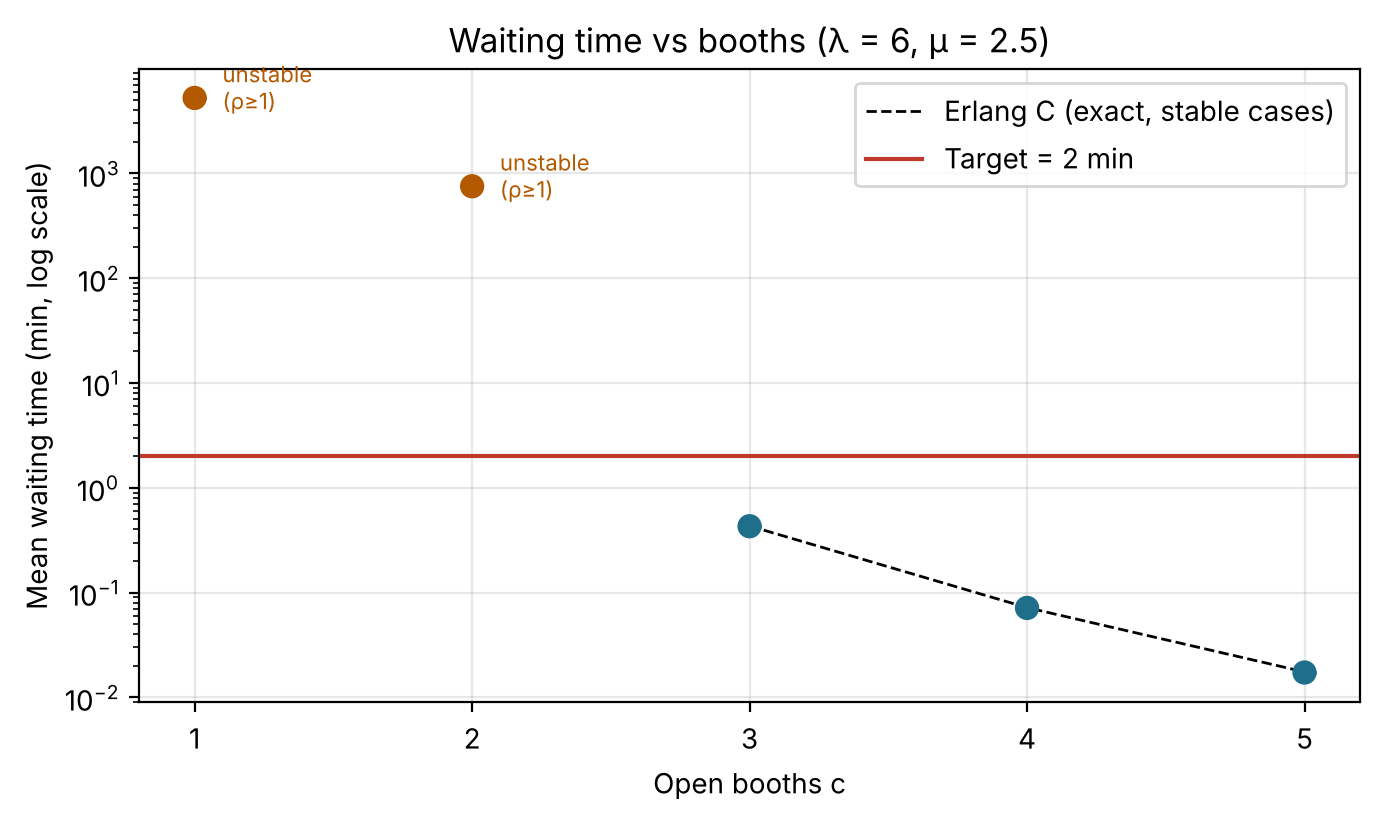

In [9]:
fig, ax = plt.subplots()
cs = list(results)
means = [results[c][1] for c in cs]; hw = [results[c][2] for c in cs]
colors = ["#b35900" if results[c][0] >= 1 else "#1f6f8b" for c in cs]
ax.errorbar(cs, means, yerr=hw, fmt="none", ecolor="#444", capsize=4, zorder=2)
ax.scatter(cs, means, c=colors, s=60, zorder=3)
st = [c for c in cs if results[c][0] < 1]
ax.plot(st, [results[c][3] for c in st], "k--", lw=1, label="Erlang C (exact, stable cases)")
ax.axhline(TARGET, color="#c0392b", lw=1.5, label=f"Target = {TARGET:g} min")
ax.set_yscale("log"); ax.set_xticks(cs)
ax.set_xlabel("Open booths c"); ax.set_ylabel("Mean waiting time (min, log scale)")
ax.set_title("Waiting time vs booths (λ = 6, μ = 2.5)")
for c in cs:
    if results[c][0] >= 1:
        ax.annotate("unstable\n(ρ≥1)", (c, results[c][1]), textcoords="offset points", xytext=(10, -4), fontsize=8, color="#b35900")
ax.legend(); plt.tight_layout(); savefig("booths_vs_wait.png"); plt.show()

## 6. Extensions

Each extension is checked before its result is used.

### 6.1 (X2) Second proof of correctness: error against sample size

A Monte Carlo estimate based on $N$ cars should have an error that shrinks like $N^{-1/2}$. On a log-log plot this is a straight line of slope $-0.5$. Here the system is the stable three-booth case, and the error is measured against the exact Erlang C value.

fitted log-log slope = -0.47 (theory: -0.5)
PASS: error shrinks as N^(-1/2)


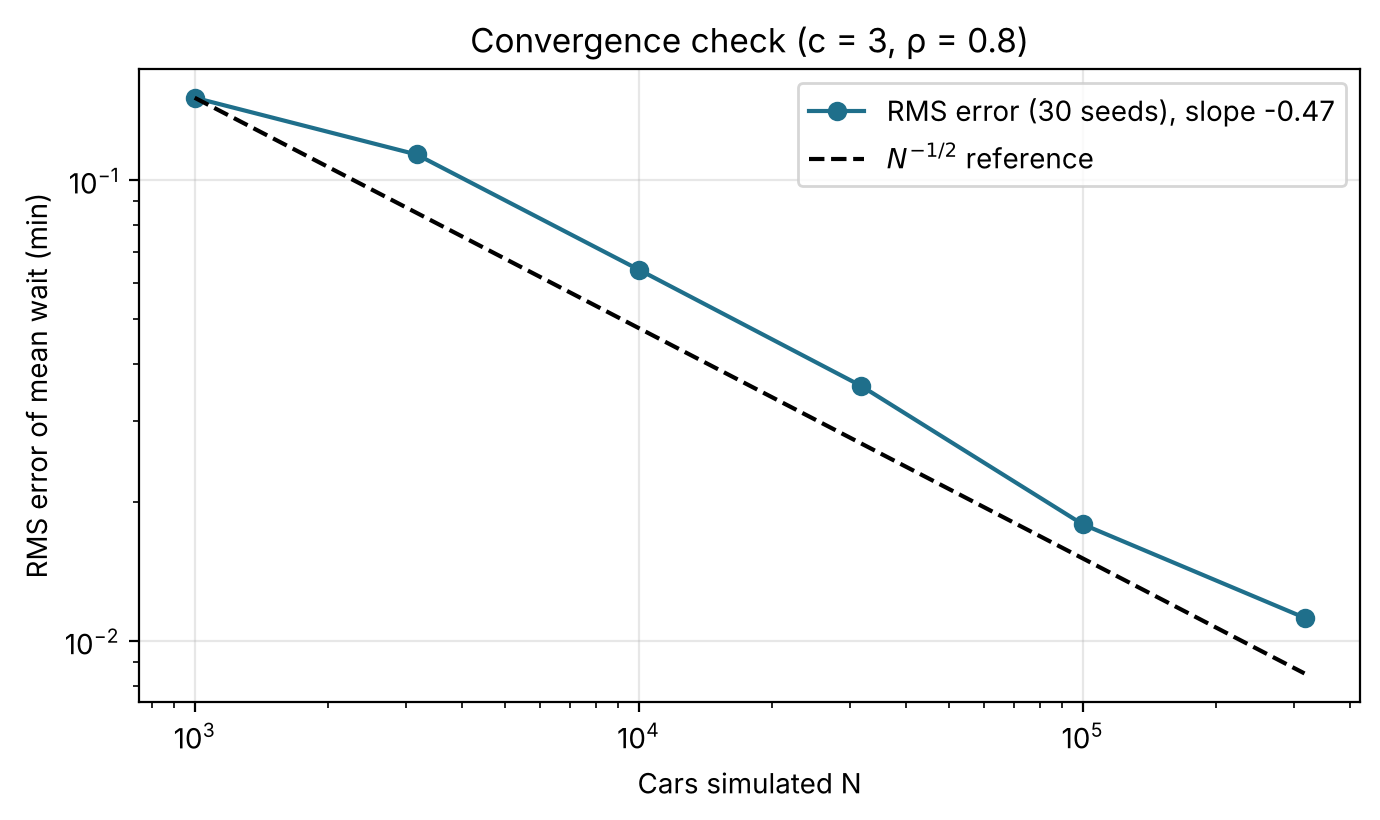

In [10]:
theory3 = wq_theory(3, LAMBDA, MU)
Ns = np.unique(np.logspace(3, 5.5, 6).astype(int))
SEEDS = 30
rmse = []
for N in Ns:
    errs = []
    for child in np.random.SeedSequence(SEED + 2).spawn(SEEDS):
        rng = np.random.default_rng(child)
        arr = np.cumsum(expo(rng, LAMBDA, N)); srv = expo(rng, MU, N)
        errs.append(simulate_fast(arr, srv, 3).mean() - theory3)
    rmse.append(math.sqrt(np.mean(np.square(errs))))
rmse = np.array(rmse)

slope, intercept = np.polyfit(np.log(Ns), np.log(rmse), 1)
print(f"fitted log-log slope = {slope:.2f} (theory: -0.5)")
assert -0.7 < slope < -0.3, "error does not shrink like N^(-1/2)"
print("PASS: error shrinks as N^(-1/2)")

fig, ax = plt.subplots()
ax.loglog(Ns, rmse, "o-", color="#1f6f8b", label=f"RMS error ({SEEDS} seeds), slope {slope:.2f}")
ax.loglog(Ns, rmse[0] * (Ns / Ns[0]) ** -0.5, "k--", label="$N^{-1/2}$ reference")
ax.set_xlabel("Cars simulated N"); ax.set_ylabel("RMS error of mean wait (min)")
ax.set_title("Convergence check (c = 3, ρ = 0.8)"); ax.legend()
plt.tight_layout(); savefig("convergence_loglog.png"); plt.show()

### 6.2 (X3) Rush hour: time-varying arrival rate by thinning

During a rush hour the arrival rate is not constant. Model it as a smooth bump

$$\lambda(t)=\lambda_{\text{base}}+(\lambda_{\text{peak}}-\lambda_{\text{base}})\,\exp\!\left[-\tfrac12\left(\frac{t-t_{\text{peak}}}{\sigma}\right)^{2}\right],\qquad 0\le t\le T,$$

with traffic building up before the peak and easing afterwards. Arrivals from this non-homogeneous Poisson process are generated by **thinning** (Lewis–Shedler): generate candidate arrivals at the constant maximum rate $\lambda_{\max}=\lambda_{\text{peak}}$, and keep a candidate at time $t$ with probability $\lambda(t)/\lambda_{\max}$.

**Check:** the thinned arrival counts must match $\int\lambda(t)\,dt$, in total and in every 10-minute bin.

In [11]:
T_END, T_PEAK, SIGMA = 180.0, 90.0, 25.0       # a 3-hour window with the peak in the middle
LAM_BASE, LAM_PEAK = 2.0, LAMBDA               # off-peak 2/min, peak 6/min

def lam_t(t):
    return LAM_BASE + (LAM_PEAK - LAM_BASE) * np.exp(-0.5 * ((t - T_PEAK) / SIGMA) ** 2)

def thinning_arrivals(rng, lam_fn, lam_max, horizon):
    """Non-homogeneous Poisson arrivals on [0, horizon] by thinning."""
    t, out = 0.0, []
    while t < horizon:
        k = max(64, int(lam_max * (horizon - t) * 1.2) + 16)
        cand = t + np.cumsum(expo(rng, lam_max, k))          # candidates at the max rate
        t = cand[-1]
        cand = cand[cand <= horizon]
        keep = rng.random(len(cand)) * lam_max <= lam_fn(cand)   # accept w.p. lambda(t)/lambda_max
        out.append(cand[keep])
    return np.concatenate(out)

# ---- check the thinning against the integral of lambda(t)
BIN = 10.0
edges = np.arange(0, T_END + BIN, BIN)
expected_bins = np.array([quad(lam_t, a, b)[0] for a, b in zip(edges[:-1], edges[1:])])
R_CHECK = 300
counts = np.array([np.histogram(thinning_arrivals(np.random.default_rng(ch), lam_t, LAM_PEAK, T_END), bins=edges)[0]
                   for ch in np.random.SeedSequence(SEED + 3).spawn(R_CHECK)])
z = (counts.mean(0) - expected_bins) / (counts.std(0, ddof=1) / math.sqrt(R_CHECK))
total_exp = quad(lam_t, 0, T_END)[0]
total_obs, total_h = mean_ci(counts.sum(1))
print(f"expected total arrivals = {total_exp:.1f}; simulated = {total_obs:.1f} ± {total_h:.1f}")
assert abs(total_obs - total_exp) / total_exp < 0.01, "total arrival count off"
assert np.max(np.abs(z)) < 4, "thinned arrival counts do not match lambda(t)"
print(f"PASS: all {len(z)} bins agree with the integral of lambda(t) (max |z| = {np.max(np.abs(z)):.2f})")

expected total arrivals = 610.6; simulated = 609.8 ± 2.9
PASS: all 18 bins agree with the integral of lambda(t) (max |z| = 2.65)


In [12]:
# ---- rush-hour experiment: how many booths now?
PEAK_WIN = (T_PEAK - 15, T_PEAK + 15)          # customers arriving within 15 min of the peak
R_RUSH = 200
rush = {}
for c in range(2, 6):
    overall, peakwin, bins = [], [], []
    for child in np.random.SeedSequence(SEED + 4).spawn(R_RUSH):
        rng = np.random.default_rng(child)
        arr = thinning_arrivals(rng, lam_t, LAM_PEAK, T_END)
        w = simulate_fast(arr, expo(rng, MU, len(arr)), c)
        overall.append(w.mean())
        sel = (arr >= PEAK_WIN[0]) & (arr <= PEAK_WIN[1])
        peakwin.append(w[sel].mean())
        idx = np.digitize(arr, edges) - 1
        bins.append([w[idx == b].mean() for b in range(len(edges) - 1)])
    rush[c] = (np.array(overall), np.array(peakwin), np.array(bins))

print(f"Rush hour (lambda from {LAM_BASE:g} up to {LAM_PEAK:g} cars/min), {R_RUSH} replications each\n")
print(f"{'c':>2} {'whole window':>20} {'peak +/-15 min':>20}  verdict (peak-window CI below target?)")
for c, (ov, pk, _) in rush.items():
    (mo, ho), (mp, hp) = mean_ci(ov), mean_ci(pk)
    print(f"{c:>2} {mo:>12.3f} ± {ho:<6.3f} {mp:>12.3f} ± {hp:<6.3f}  {'meets target' if mp + hp < TARGET else 'misses target'}")
c_rush = min(c for c, (_, pk, _) in rush.items() if mean_ci(pk)[0] + mean_ci(pk)[1] < TARGET)
print(f"\nWith rush-hour arrivals, at least {c_rush} booths are needed to keep the peak-window mean wait under {TARGET:g} min.")
print(f"(For reference, the steady-state Erlang C wait at the peak rate with c=3 is {wq_theory(3, LAMBDA, MU):.3f} min; "
      f"the transient rush-hour wait is lower because the queue never reaches steady state.)")

Rush hour (lambda from 2 up to 6 cars/min), 200 replications each

 c         whole window       peak +/-15 min  verdict (peak-window CI below target?)
 2        2.592 ± 0.197         4.336 ± 0.297   misses target
 3        0.148 ± 0.014         0.353 ± 0.041   meets target
 4        0.026 ± 0.002         0.062 ± 0.007   meets target
 5        0.006 ± 0.001         0.015 ± 0.002   meets target

With rush-hour arrivals, at least 3 booths are needed to keep the peak-window mean wait under 2 min.
(For reference, the steady-state Erlang C wait at the peak rate with c=3 is 0.431 min; the transient rush-hour wait is lower because the queue never reaches steady state.)


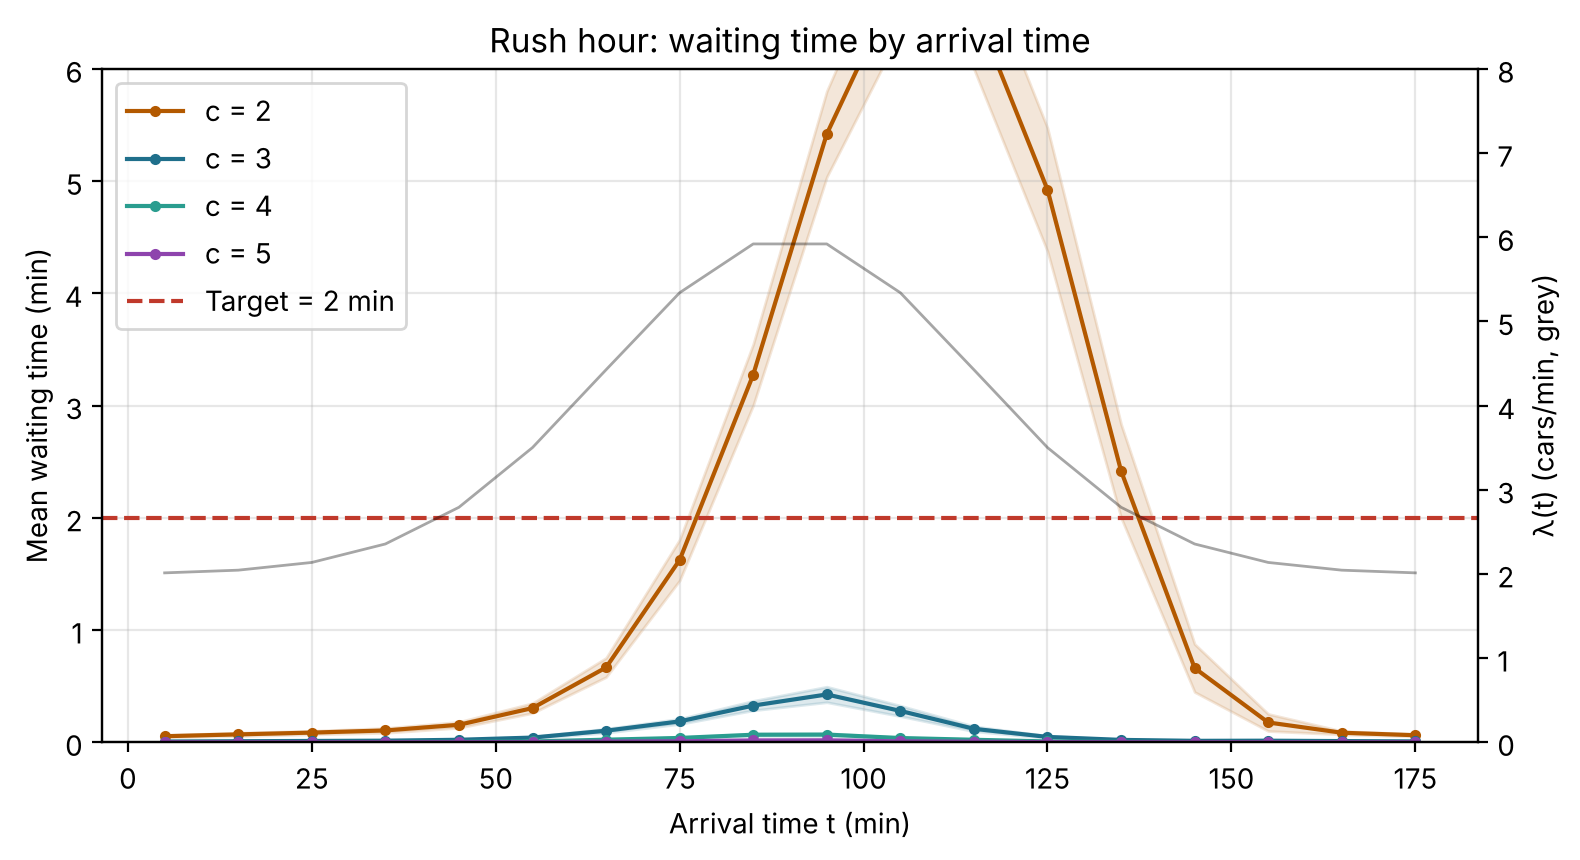

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.4))
mid = 0.5 * (edges[:-1] + edges[1:])
for c, col in zip(range(2, 6), ["#b35900", "#1f6f8b", "#2a9d8f", "#8e44ad"]):
    b = rush[c][2]; m = b.mean(0); h = stats.t.ppf(0.975, R_RUSH - 1) * b.std(0, ddof=1) / math.sqrt(R_RUSH)
    ax.plot(mid, m, "-o", ms=3, color=col, label=f"c = {c}")
    ax.fill_between(mid, m - h, m + h, color=col, alpha=0.15)
ax.axhline(TARGET, color="#c0392b", lw=1.5, ls="--", label=f"Target = {TARGET:g} min")
ax.set_ylim(0, 6); ax.set_xlabel("Arrival time t (min)"); ax.set_ylabel("Mean waiting time (min)")
ax2 = ax.twinx(); ax2.plot(mid, lam_t(mid), color="k", alpha=0.35, lw=1); ax2.set_ylabel("λ(t) (cars/min, grey)")
ax2.set_ylim(0, 8); ax2.grid(False)
ax.set_title("Rush hour: waiting time by arrival time"); ax.legend(loc="upper left")
plt.tight_layout(); savefig("rush_hour.png"); plt.show()

### 6.3 (X5) Sensitivity: which parameter matters most?

The inputs $\lambda$ and $\mu$ are estimates, so the answer should be tested against small errors in them. Each parameter is changed by $\pm5\%$ and $\pm10\%$ while the other is held fixed, using **common random numbers** (the same underlying random draws in every scenario, so differences are due to the parameter, not to noise). The effect is summarised by the **elasticity** $\varepsilon_p=\dfrac{\Delta W_q/W_q}{\Delta p/p}$ (percent change in wait per percent change in the parameter), estimated by a central difference at $\pm5\%$ and compared with the same quantity computed from Erlang C.

In [14]:
C_SENS, N_S, WARM_S, R_S = 3, 60_000, 5_000, 30
unit = []                                            # unit-rate exponential draws, reused in every scenario
for child in np.random.SeedSequence(SEED + 5).spawn(R_S):
    rng = np.random.default_rng(child)
    unit.append((expo(rng, 1.0, N_S), expo(rng, 1.0, N_S)))

def sens_wait(lam, mu):
    """Per-replication mean wait with common random numbers (scale the unit draws)."""
    out = []
    for ia_u, sv_u in unit:
        arr = np.cumsum(ia_u / lam)                  # interarrival ~ Exp(lam)
        out.append(simulate_fast(arr, sv_u / mu, C_SENS)[WARM_S:].mean())
    return np.array(out)

deltas = [-0.10, -0.05, 0.0, 0.05, 0.10]
sim_w = {("lam", d): sens_wait(LAMBDA * (1 + d), MU) for d in deltas}
sim_w.update({("mu", d): sens_wait(LAMBDA, MU * (1 + d)) for d in deltas if d != 0})
base = sim_w[("lam", 0.0)]; sim_w[("mu", 0.0)] = base
th_w = {("lam", d): wq_theory(C_SENS, LAMBDA * (1 + d), MU) for d in deltas}
th_w.update({("mu", d): wq_theory(C_SENS, LAMBDA, MU * (1 + d)) for d in deltas})

print(f"c = {C_SENS}, base lambda = {LAMBDA}, mu = {MU}: Erlang C wait = {th_w[('lam', 0.0)]:.4f} min\n")
print(f"{'parameter':>10} {'change':>7} {'simulated Wq':>13} {'Erlang C':>9} {'sim % change':>13} {'theory % change':>16}")
for p in ("lam", "mu"):
    for d in deltas:
        s = sim_w[(p, d)].mean()
        print(f"{p:>10} {d:>+7.0%} {s:>13.4f} {th_w[(p, d)]:>9.4f} {100*(s/base.mean()-1):>12.1f}% {100*(th_w[(p, d)]/th_w[('lam', 0.0)]-1):>15.1f}%")

def elasticity_sim(p):
    per_rep = (sim_w[(p, 0.05)] - sim_w[(p, -0.05)]) / base / 0.10     # paired across replications
    return mean_ci(per_rep)
def elasticity_th(p):
    return (th_w[(p, 0.05)] - th_w[(p, -0.05)]) / th_w[("lam", 0.0)] / 0.10

e_lam, h_lam = elasticity_sim("lam"); e_mu, h_mu = elasticity_sim("mu")
t_lam, t_mu = elasticity_th("lam"), elasticity_th("mu")
print(f"\nelasticity of wait w.r.t. lambda: simulated {e_lam:+.2f} ± {h_lam:.2f} | Erlang C {t_lam:+.2f}")
print(f"elasticity of wait w.r.t. mu    : simulated {e_mu:+.2f} ± {h_mu:.2f} | Erlang C {t_mu:+.2f}")

# checks: simulation reproduces the analytic sensitivities, and mu matters more than lambda
assert abs(e_lam - t_lam) / abs(t_lam) < 0.15 and abs(e_mu - t_mu) / abs(t_mu) < 0.15, "elasticities disagree with Erlang C"
assert abs(e_mu) > abs(e_lam), "expected the service rate to have the larger effect"
print("PASS: simulated elasticities match Erlang C within 15%, and |elasticity(mu)| > |elasticity(lambda)|")

c = 3, base lambda = 6.0, mu = 2.5: Erlang C wait = 0.4315 min

 parameter  change  simulated Wq  Erlang C  sim % change  theory % change
       lam    -10%        0.2494    0.2486        -42.5%           -42.4%
       lam     -5%        0.3251    0.3241        -25.1%           -24.9%
       lam     +0%        0.4339    0.4315          0.0%             0.0%
       lam     +5%        0.6002    0.5945         38.3%            37.8%
       lam    +10%        0.8762    0.8689        101.9%           101.4%
        mu    -10%        1.0728    1.0633        147.2%           146.5%
        mu     -5%        0.6434    0.6373         48.3%            47.7%
        mu     +0%        0.4339    0.4315          0.0%             0.0%
        mu     +5%        0.3137    0.3127        -27.7%           -27.5%
        mu    +10%        0.2377    0.2369        -45.2%           -45.1%

elasticity of wait w.r.t. lambda: simulated +6.32 ± 0.16 | Erlang C +6.27
elasticity of wait w.r.t. mu    : simulated -7.

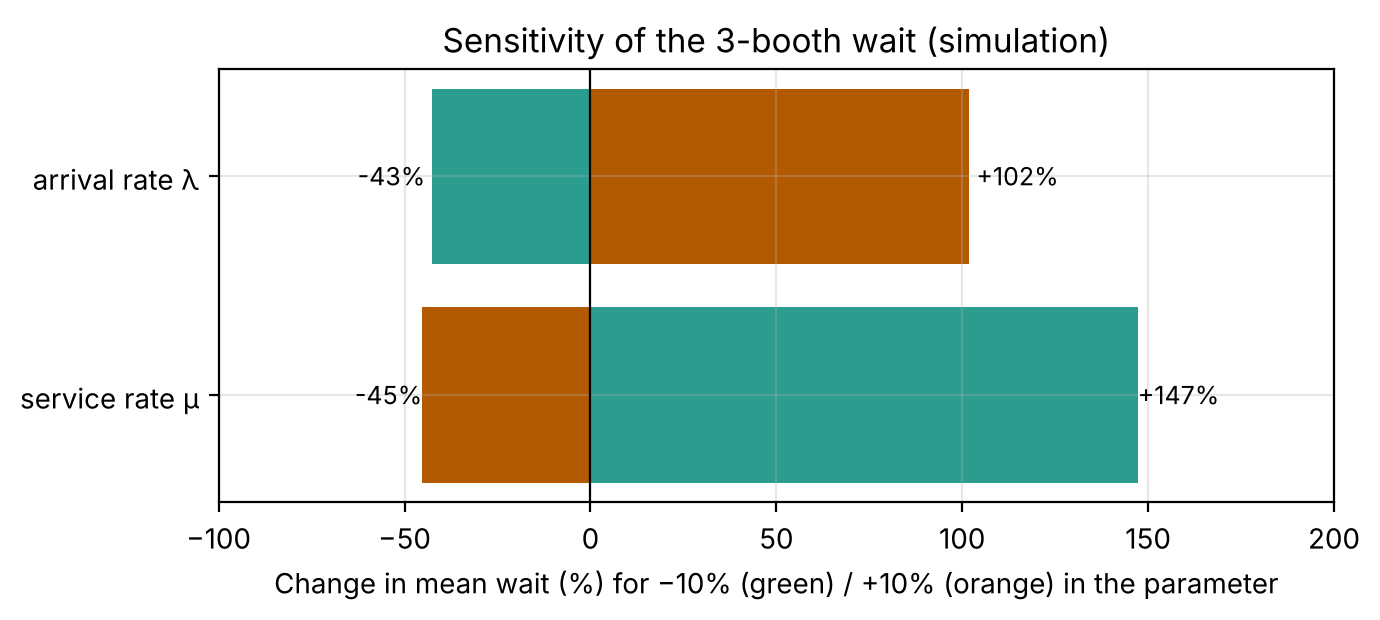

Smallest c with Erlang C wait < target, for combined parameter errors:
  lambda     mu  rho(c=3)  c needed
    5.40  2.250      0.80         3
    5.40  2.500      0.72         3
    5.40  2.750      0.65         3
    6.00  2.250      0.89         3
    6.00  2.500      0.80         3
    6.00  2.750      0.73         3
    6.60  2.250      0.98         4
    6.60  2.500      0.88         3
    6.60  2.750      0.80         3


In [15]:
# Tornado chart: % change in the three-booth wait for +/-10% in each parameter
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, (p, name) in enumerate([("mu", "service rate μ"), ("lam", "arrival rate λ")]):
    lo = 100 * (sim_w[(p, -0.10)].mean() / base.mean() - 1); hi = 100 * (sim_w[(p, 0.10)].mean() / base.mean() - 1)
    ax.barh(k, lo, color="#2a9d8f"); ax.barh(k, hi, color="#b35900")
    ax.text(lo, k, f"{lo:+.0f}% ", ha="right" if lo < 0 else "left", va="center", fontsize=9)
    ax.text(hi, k, f" {hi:+.0f}%", ha="left" if hi > 0 else "right", va="center", fontsize=9)
ax.set_yticks([0, 1]); ax.set_yticklabels(["service rate μ", "arrival rate λ"])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Change in mean wait (%) for −10% (green) / +10% (orange) in the parameter")
ax.set_title("Sensitivity of the 3-booth wait (simulation)"); ax.set_xlim(-100, 200)
plt.tight_layout(); savefig("sensitivity.png"); plt.show()

# Does the recommended number of booths survive errors in lambda and mu? (Erlang C)
print("Smallest c with Erlang C wait < target, for combined parameter errors:")
print(f"{'lambda':>8} {'mu':>6} {'rho(c=3)':>9} {'c needed':>9}")
for dl in (-0.10, 0.0, 0.10):
    for dm in (-0.10, 0.0, 0.10):
        l, m = LAMBDA * (1 + dl), MU * (1 + dm)
        need = next(c for c in range(1, 12) if wq_theory(c, l, m) < TARGET)
        print(f"{l:>8.2f} {m:>6.3f} {l/(3*m):>9.2f} {need:>9}")

## 7. Discussion and limitations

**Answer.** At the example peak demand ($\lambda=6$ cars/min, $\mu=2.5$ cars/min per booth) one booth ($\rho=2.4$) and two booths ($\rho=1.2$) are unstable: queues grow without limit. Three booths give a mean wait of about 0.43 min (well under the 2-minute target) and four or five give almost none. **At least 3 booths** must be open, and the simulation agrees with Erlang C to within its confidence interval.

**Extensions.** Under a rush-hour profile peaking at the same 6 cars/min, the queue has no time to reach steady state, so waits lag the demand curve and the peak-window wait is lower than the steady-state value. The sensitivity study shows the wait is more sensitive to the service rate $\mu$ than to the arrival rate $\lambda$ (because $W_q=f(\lambda/\mu)/\mu$, a change in $\mu$ acts twice), and the three-booth recommendation is only fragile when $\lambda$ is high and $\mu$ is low together.

**Limitations**

- Exponential service times are more variable than real payment times, so waits are somewhat overestimated (safe side). A general-service (M/G/c) model would need a different verification.
- Booths are treated as one shared queue; in reality cars choose lanes, which makes waits slightly longer.
- $\lambda$ and $\mu$ are example values. They should be replaced by measured counts and service times before any real decision.
- Finite-run results for unstable cases ($c=1,2$) depend on run length and are shown only to demonstrate instability.

**Web demo reference value:** with the default settings ($\lambda=6$, $\mu=2.5$, $c=3$) the web demo should reproduce a mean wait of **0.43 min** (Erlang C: 0.431 min; section 5).

In [16]:
print(f"Total notebook run time: {time.time() - T_START:.0f} s")

Total notebook run time: 44 s


## 8. References

1. D. Gross, J. F. Shortle, J. M. Thompson and C. M. Harris, *Fundamentals of Queueing Theory*, 4th ed. Hoboken, NJ, USA: Wiley, 2008.
2. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill Education, 2015.
3. J. Banks, J. S. Carson II, B. L. Nelson and D. M. Nicol, *Discrete-Event System Simulation*, 5th ed. Upper Saddle River, NJ, USA: Prentice Hall, 2010.
4. L. Devroye, *Non-Uniform Random Variate Generation*. New York, NY, USA: Springer-Verlag, 1986, doi: 10.1007/978-1-4613-8643-8.
5. P. A. W. Lewis and G. S. Shedler, "Simulation of nonhomogeneous Poisson processes by thinning," *Naval Research Logistics Quarterly*, vol. 26, no. 3, pp. 403–413, 1979, doi: 10.1002/nav.3800260304.
6. C. R. Harris *et al.*, "Array programming with NumPy," *Nature*, vol. 585, no. 7825, pp. 357–362, 2020, doi: 10.1038/s41586-020-2649-2.
7. P. Virtanen *et al.*, "SciPy 1.0: fundamental algorithms for scientific computing in Python," *Nature Methods*, vol. 17, no. 3, pp. 261–272, 2020, doi: 10.1038/s41592-019-0686-2.
8. J. D. Hunter, "Matplotlib: A 2D graphics environment," *Computing in Science & Engineering*, vol. 9, no. 3, pp. 90–95, 2007, doi: 10.1109/MCSE.2007.55.

(Full list: see [REFERENCES.md](../REFERENCES.md).)